# Laboratorio 10 - Deep Learning

- Juan Diego Solís Martínez - 23720
- Victor Manuel Pérez Chávez - 23731
- Diego Oswaldo Flores Rivas - 23714

## Task 1

In [1]:
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
from torchvision import models, transforms

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
print("Semilla aleatoria:", SEED)

Semilla aleatoria: 42


### Task 1.1

Se carga ResNet-18 preentrenado en ImageNet en modo evaluación, se preprocesan las tres imágenes (lado corto 256, recorte central 224, normalización de ImageNet) y se reportan sus cinco clases más probables. Para la imagen (c) se define el recuadro del objeto.

In [2]:
pesos = models.ResNet18_Weights.IMAGENET1K_V1
modelo = models.resnet18(weights=pesos).eval()
clases = pesos.meta["categories"]

MEDIA, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)
recorte = transforms.Compose([transforms.Resize(256), transforms.CenterCrop(224)])
normalizar = transforms.Compose([transforms.ToTensor(), transforms.Normalize(MEDIA, STD)])

# Fuentes de las imágenes en images/fuentes.txt
rutas = {"a": "images/a_objeto.jpg", "b": "images/b_dos_objetos.jpg", "c": "images/c_fuera_contexto.jpg"}
imgs = {k: recorte(Image.open(r).convert("RGB")) for k, r in rutas.items()}   # imágenes 224 x 224
x = {k: normalizar(im).unsqueeze(0) for k, im in imgs.items()}

top1, probs = {}, {}
for k in rutas:
    with torch.no_grad():
        prob = F.softmax(modelo(x[k]), dim=1)[0]
    p5, c5 = prob.topk(5)
    top1[k], probs[k] = c5[0].item(), prob
    print(f"Imagen ({k}) - {rutas[k]}")
    for p, c in zip(p5, c5):
        print(f"   {c.item():4d}  {clases[c]:30s} {p.item():.4f}")

Imagen (a) - images/a_objeto.jpg
    281  tabby                          0.3879
    282  tiger cat                      0.3490
    285  Egyptian cat                   0.2221
    287  lynx                           0.0051
    728  plastic bag                    0.0018
Imagen (b) - images/b_dos_objetos.jpg
    208  Labrador retriever             0.3702
    539  doormat                        0.0393
    588  hamper                         0.0392
    285  Egyptian cat                   0.0380
    209  Chesapeake Bay retriever       0.0356
Imagen (c) - images/c_fuera_contexto.jpg
    171  Italian greyhound              0.1692
    162  beagle                         0.1083
    359  black-footed ferret            0.0717
    383  Madagascar cat                 0.0704
    284  Siamese cat                    0.0498


Recuadro de (c): (74, 120, 118, 204)


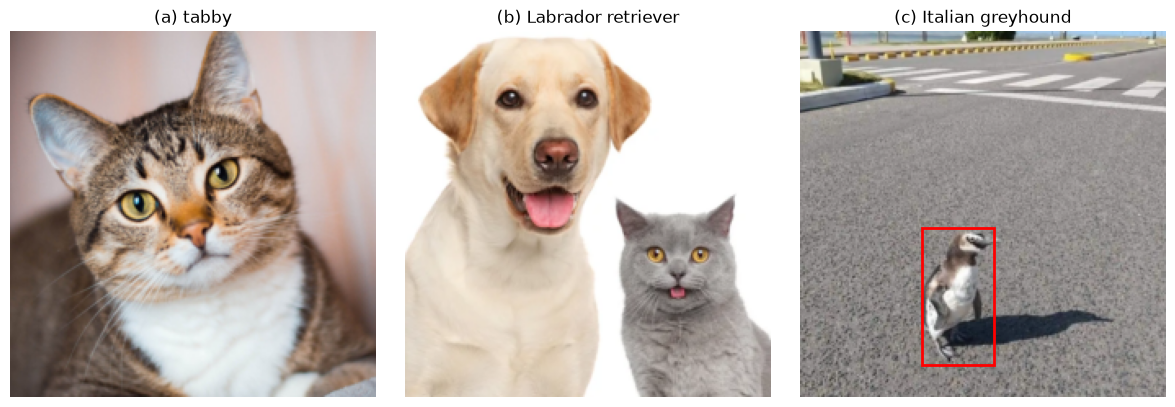

In [3]:
# Recuadro del objeto en la imagen (c), en coordenadas de 224 x 224: (x0, y0, x1, y1)
caja_c = (74, 120, 118, 204)   # pingüino
print("Recuadro de (c):", caja_c)

fig, ax = plt.subplots(1, 3, figsize=(12, 4))
for a, k in zip(ax, rutas):
    a.imshow(imgs[k]); a.set_title(f"({k}) {clases[top1[k]]}"); a.axis("off")
x0, y0, x1, y1 = caja_c
ax[2].add_patch(patches.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, color="red", lw=2))
plt.tight_layout(); plt.show()

### Task 1.2

Se implementa Grad-CAM con un hook de avance (activaciones $A$ de `layer4`) y uno de retroceso ($\partial y^c/\partial A$), retropropagando desde el logit. Se superpone el mapa de la clase más probable de cada imagen y, en (b), también el de la clase del segundo objeto.

In [4]:
cache = {}
modelo.layer4.register_forward_hook(lambda m, inp, out: cache.__setitem__("A", out))                  # A: (1, 512, 7, 7)
modelo.layer4.register_full_backward_hook(lambda m, g_in, g_out: cache.__setitem__("dA", g_out[0]))  # dy^c/dA

def gradcam(xin, c):
    modelo.zero_grad()
    logits = modelo(xin)
    logits[0, c].backward()                       # desde el logit y^c, antes del softmax
    A, dA = cache["A"][0].detach(), cache["dA"][0].detach()
    alpha = dA.mean(dim=(1, 2))                   # alpha_k^c = (1/Z) sum_ij dy^c/dA_ij^k
    L_crudo = (alpha[:, None, None] * A).sum(0)   # sum_k alpha_k^c A^k (7 x 7, sin ReLU)
    L = F.relu(L_crudo)                           # L^c = ReLU(sum_k alpha_k^c A^k)
    L = F.interpolate(L[None, None], size=(224, 224), mode="bilinear", align_corners=False)[0, 0]
    L = (L - L.min()) / (L.max() - L.min())       # normalización mínimo-máximo
    return {"L": L.numpy(), "L_crudo": L_crudo, "alpha": alpha, "A": A, "logit": logits[0, c].item()}

def superponer(ax, k, mapa, titulo):
    ax.imshow(imgs[k]); ax.imshow(mapa, cmap="jet", alpha=0.45); ax.set_title(titulo); ax.axis("off")

(b) clase top-1: Labrador retriever | segunda clase: Egyptian cat (p = 0.0380)


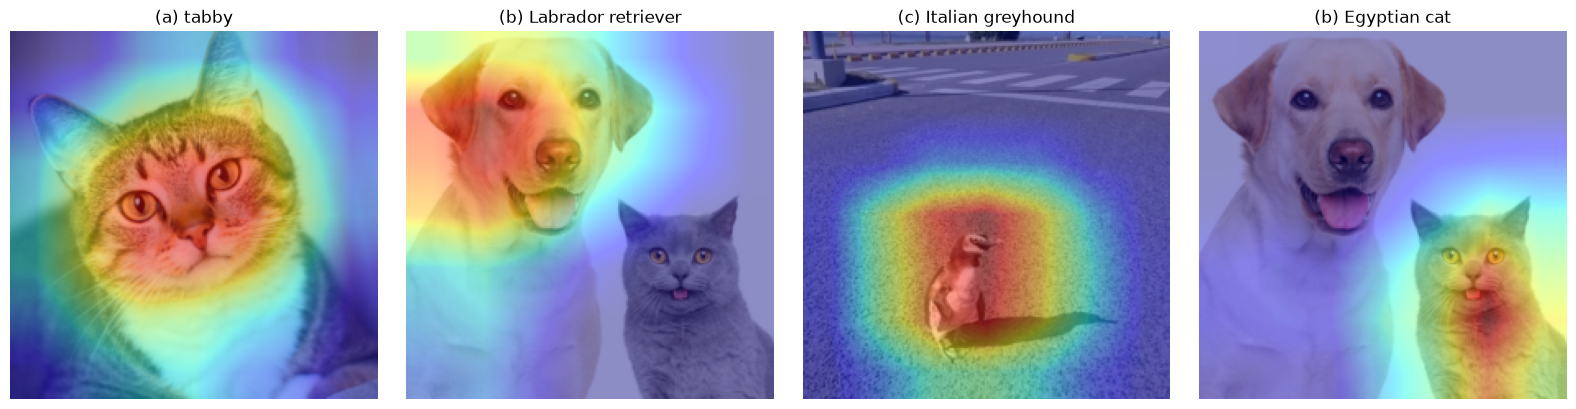

In [5]:
# Clase del segundo objeto de (b): la clase de gato (281-285) o de perro (151-268) más probable, la que no sea la top-1
gatos, perros = range(281, 286), range(151, 269)
clase2_b = max(gatos if top1["b"] in perros else perros, key=lambda i: probs["b"][i].item())
print(f"(b) clase top-1: {clases[top1['b']]} | segunda clase: {clases[clase2_b]} (p = {probs['b'][clase2_b]:.4f})")

gc = {k: gradcam(x[k], top1[k]) for k in rutas}
gc["b2"] = gradcam(x["b"], clase2_b)

fig, ax = plt.subplots(1, 4, figsize=(16, 4))
for a, k in zip(ax[:3], rutas):
    superponer(a, k, gc[k]["L"], f"({k}) {clases[top1[k]]}")
superponer(ax[3], "b", gc["b2"]["L"], f"(b) {clases[clase2_b]}")
plt.tight_layout(); plt.show()

### Task 1.3

Se calcula CAM directamente con los pesos de `fc` (sin gradientes) y se verifican la descomposición del logit y la equivalencia con Grad-CAM.

In [6]:
W, b = modelo.fc.weight.detach(), modelo.fc.bias.detach()   # W: (1000, 512)
Z = 49

for k in rutas:
    c, A = top1[k], gc[k]["A"]
    # a. M_ij^c = sum_k w_k^c A_ij^k
    M = torch.einsum("k,kij->ij", W[c], A)
    # b. (1/Z) sum_ij M_ij^c + b_c = y^c
    y_cam = M.sum().item() / Z + b[c].item()
    # c. Z * L^c (sin ReLU ni normalización) contra M^c
    err_c = (Z * gc[k]["L_crudo"] - M).abs().max().item()
    # d. ReLU y mínimo-máximo en ambos mapas (7 x 7)
    mm = lambda t: (F.relu(t) - F.relu(t).min()) / (F.relu(t).max() - F.relu(t).min())
    err_d = (mm(gc[k]["L_crudo"]) - mm(M)).abs().max().item()
    gc[k]["M"] = M
    print(f"Imagen ({k}) - clase {clases[c]}")
    print(f"   b. (1/Z) sum M + b_c = {y_cam:.6f}   logit y^c = {gc[k]['logit']:.6f}   error = {abs(y_cam - gc[k]['logit']):.3e}")
    print(f"   c. max |Z L^c - M^c| = {err_c:.3e}")
    print(f"   d. max |norm(ReLU(L^c)) - norm(ReLU(M^c))| = {err_d:.3e}")

Imagen (a) - clase tabby
   b. (1/Z) sum M + b_c = 11.502189   logit y^c = 11.502191   error = 2.018e-06
   c. max |Z L^c - M^c| = 1.144e-05
   d. max |norm(ReLU(L^c)) - norm(ReLU(M^c))| = 3.576e-07
Imagen (b) - clase Labrador retriever
   b. (1/Z) sum M + b_c = 9.181669   logit y^c = 9.181671   error = 1.674e-06
   c. max |Z L^c - M^c| = 1.144e-05
   d. max |norm(ReLU(L^c)) - norm(ReLU(M^c))| = 4.172e-07
Imagen (c) - clase Italian greyhound
   b. (1/Z) sum M + b_c = 9.117519   logit y^c = 9.117518   error = 9.423e-07
   c. max |Z L^c - M^c| = 7.629e-06
   d. max |norm(ReLU(L^c)) - norm(ReLU(M^c))| = 3.576e-07


### Task 1.4

Esta sección es de análisis: aquí solo se calculan los números que se usan en las respuestas del documento.

**a.** $\alpha_k^c$ contra $w_k^c/Z$ en los cinco canales de mayor peso para la imagen (a).

In [7]:
c = top1["a"]
canales = W[c].topk(5).indices
alpha = gc["a"]["alpha"]
print(f"Clase de (a): {clases[c]}")
print(f"{'canal':>6} {'alpha_k^c':>14} {'w_k^c / Z':>14} {'error relativo':>16}")
for kk in canales:
    a_k, w_k = alpha[kk].item(), W[c, kk].item() / Z
    print(f"{kk.item():6d} {a_k:14.8e} {w_k:14.8e} {abs(a_k - w_k) / abs(w_k):16.3e}")
print("Épsilon de float32:", torch.finfo(torch.float32).eps)

Clase de (a): tabby
 canal      alpha_k^c      w_k^c / Z   error relativo
   156 5.89546002e-03 5.89546014e-03        1.934e-08
   298 5.77564817e-03 5.77564811e-03        9.872e-09
   167 5.40834107e-03 5.40834118e-03        2.109e-08
   173 4.49762493e-03 4.49762417e-03        1.690e-07
   301 4.35343059e-03 4.35343081e-03        5.021e-08
Épsilon de float32: 1.1920928955078125e-07


**b.** IoU entre el 20 % de píxeles de mayor valor de los dos mapas de la imagen (b).

Clases: Labrador retriever vs Egyptian cat
IoU de los conjuntos del 20% superior: 0.0000
Correlación entre los mapas 7x7 crudos: -0.7034


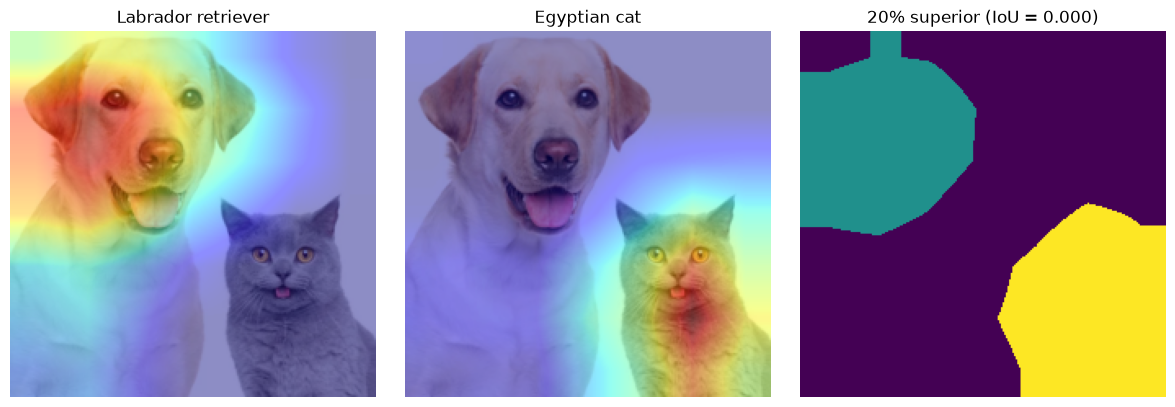

In [8]:
m1, m2 = gc["b"]["L"], gc["b2"]["L"]
s1, s2 = m1 >= np.quantile(m1, 0.8), m2 >= np.quantile(m2, 0.8)
iou = (s1 & s2).sum() / (s1 | s2).sum()
print(f"Clases: {clases[top1['b']]} vs {clases[clase2_b]}")
print(f"IoU de los conjuntos del 20% superior: {iou:.4f}")
print(f"Correlación entre los mapas 7x7 crudos: {np.corrcoef(gc['b']['L_crudo'].numpy().ravel(), gc['b2']['L_crudo'].numpy().ravel())[0, 1]:.4f}")

fig, ax = plt.subplots(1, 3, figsize=(12, 4))
superponer(ax[0], "b", m1, clases[top1["b"]])
superponer(ax[1], "b", m2, clases[clase2_b])
ax[2].imshow(s1.astype(int) + 2 * s2.astype(int), cmap="viridis"); ax[2].set_title(f"20% superior (IoU = {iou:.3f})"); ax[2].axis("off")
plt.tight_layout(); plt.show()

**c.** Masa del mapa dentro del recuadro de (c) y prueba causal con el fondo en gris.

Fracción de la masa del mapa dentro del recuadro: 0.2245 (el recuadro ocupa 0.0737 del área)
p(Italian greyhound) original:   0.1692
p(Italian greyhound) fondo gris: 0.0024   cambio = -0.1668
Top-5 con fondo gris: [('black-footed ferret', 0.1816), ('badger', 0.1159), ('weasel', 0.1005), ('polecat', 0.0841), ('water ouzel', 0.0459)]


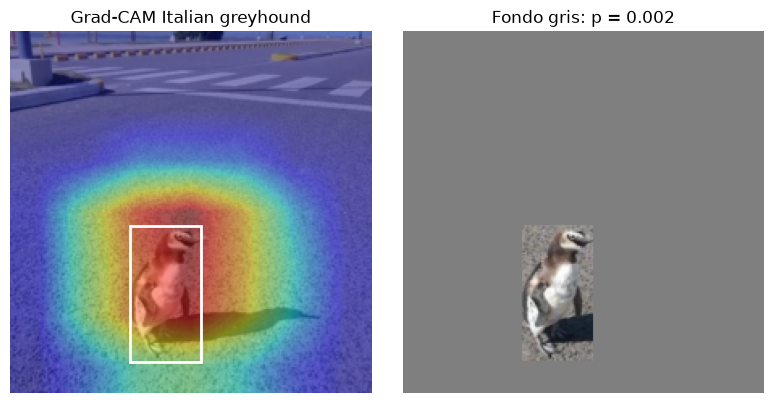

In [9]:
x0, y0, x1, y1 = caja_c
L_c = gc["c"]["L"]
masa = L_c[y0:y1, x0:x1].sum() / L_c.sum()
area = (x1 - x0) * (y1 - y0) / 224**2
print(f"Fracción de la masa del mapa dentro del recuadro: {masa:.4f} (el recuadro ocupa {area:.4f} del área)")

# Prueba causal: todo lo que queda fuera del recuadro pasa a gris medio (0.5 antes de normalizar)
pix = transforms.ToTensor()(imgs["c"])
gris = torch.full_like(pix, 0.5)
gris[:, y0:y1, x0:x1] = pix[:, y0:y1, x0:x1]
x_gris = transforms.Normalize(MEDIA, STD)(gris).unsqueeze(0)

c = top1["c"]
with torch.no_grad():
    p_orig = F.softmax(modelo(x["c"]), 1)[0]
    p_gris = F.softmax(modelo(x_gris), 1)[0]
print(f"p({clases[c]}) original:   {p_orig[c]:.4f}")
print(f"p({clases[c]}) fondo gris: {p_gris[c]:.4f}   cambio = {p_gris[c] - p_orig[c]:+.4f}")
p5, c5 = p_gris.topk(5)
print("Top-5 con fondo gris:", [(clases[i], round(p.item(), 4)) for p, i in zip(p5, c5)])

fig, ax = plt.subplots(1, 2, figsize=(8, 4))
superponer(ax[0], "c", L_c, f"Grad-CAM {clases[c]}")
ax[0].add_patch(patches.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, color="white", lw=2))
ax[1].imshow(gris.permute(1, 2, 0)); ax[1].set_title(f"Fondo gris: p = {p_gris[c]:.3f}"); ax[1].axis("off")
plt.tight_layout(); plt.show()